# 06 · Model 4: Multi-Layer Perceptron
**Owner:** Sheetal · **Family:** Neural network · **Script:** `models/train_mlp.py`

**Why this model for PathSnap?** A neural network learns smooth non-linear combinations of the features. Its probabilities come straight from a cross-entropy-trained output, which is useful for HMM emissions.

**Strengths:** learns non-linear interactions, compact model (about 90 kB), fast inference, well-calibrated probabilities (best log loss of the 5).

**Limitations:** needs scaling, is sensitive to learning rate and architecture, and is slower to train. It was trained on a 40% sample to keep 5-fold CV affordable.

**Loss / objective:** binary cross-entropy (log loss) + L2 (alpha=1e-4), optimised with Adam (lr 1e-3, batch 512), with early stopping on a 10% validation split.

**Protocol (same for all 5 models, `models/common.py`):** 5-fold **GroupKFold by trip** on the 78 clean training trips (trips 54 and 33 excluded) → refit on all of them → evaluate on the 10 student_test trips (every GPS point). Primary metric: **observation-level Top-1 accuracy**. Only one fixed configuration per model: **no grid or random search** (organiser rule). Only the selected model is tuned, with Bayesian optimisation.

In [1]:
import os, sys
# run from the repository root regardless of where the notebook lives
_p = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(_p, "pathsnap")):
    _p = os.path.dirname(_p)
os.chdir(_p); sys.path.insert(0, _p)
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110
print("repo root:", os.getcwd())
from models.train_mlp import est, cfg
from models.common import run_experiment
from pathsnap.features import FEATURE_COLUMNS
print("hyperparameters:", cfg)
est

repo root: C:\Users\shrey\OneDrive\Documents\ML Hackathon\PathSnap_7_H


hyperparameters: {'hidden_layer_sizes': (64, 32), 'activation': 'relu', 'alpha': 0.0001, 'learning_rate_init': 0.001, 'batch_size': 512, 'max_iter': 60, 'early_stopping': True, 'n_iter_no_change': 5, 'train_sample_frac': 0.4}


,steps,"[('standardscaler', ...), ('mlpclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,hidden_layer_sizes,"(64, ...)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001


## Train, cross-validate and evaluate

In [2]:
row, model = run_experiment("mlp", "Neural network", est, cfg, train_sample_frac=0.4)
pd.Series(row).drop("config_json")

[mlp] train rows=235,467 trips=78 | test rows=131,630


[mlp] CV macroF1=0.9193±0.0199 CV top1=0.8688 | test top1=0.8707 macroF1=0.9223 logloss=0.0957 cont=0.9541 | fit 86.7s, infer 11 ms/trip


model                                   mlp
family                       Neural network
cv_macro_f1_mean                   0.919331
cv_macro_f1_std                    0.019912
cv_top1_mean                       0.868759
cv_top1_std                        0.031884
cv_logloss                         0.108461
train_top1                         0.885455
train_macro_f1                     0.932928
test_top1                          0.870668
test_macro_f1                      0.922301
test_precision                     0.868599
test_recall                        0.865644
test_logloss                       0.095674
test_cand_miss_rate                0.002818
test_route_continuity_clf          0.954138
train_time_s                          86.74
infer_ms_per_trip                     11.11
train_rows                           235467
seed                                     42
dtype: object

In [3]:
log = json.load(open("results/model_runs/mlp.json"))
folds = pd.DataFrame(log["folds"]); display(folds.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
folds.plot(x="fold", y=["top1_accuracy", "macro_f1"], marker="o", ax=ax[0]); ax[0].set_title("Per-fold CV scores"); ax[0].set_ylim(0.75, 1)
bars = pd.Series({"train (fit data)": row["train_top1"], "CV (mean)": row["cv_top1_mean"], "student_test": row["test_top1"]})
bars.plot.bar(ax=ax[1], color=["C2", "C0", "C1"]); ax[1].set_ylim(0.75, 1); ax[1].set_title("Top-1: train vs CV vs test (over/underfitting)")
for i, v in enumerate(bars): ax[1].text(i, v + .005, f"{v:.3f}", ha="center")
plt.tight_layout(); plt.show()

,macro_f1,precision,recall,logloss,top1_accuracy,candidate_miss_rate,fold,fit_s
0,0.9025,0.8442,0.8279,0.1369,0.8341,0.0111,0,13.49
1,0.9373,0.9127,0.8709,0.0746,0.9025,0.0023,1,34.47
2,0.9274,0.9012,0.8498,0.0937,0.8798,0.0025,2,93.66
3,0.8939,0.8438,0.7919,0.1329,0.8359,0.0245,3,47.17
4,0.9355,0.9066,0.8840,0.1042,0.8917,0.0082,4,51.30


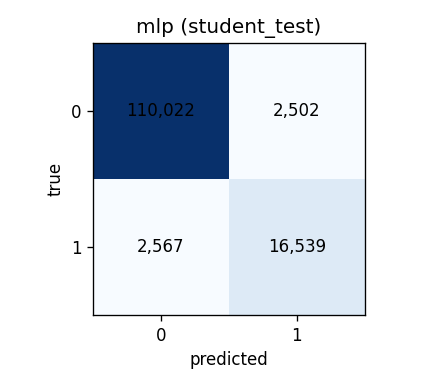

In [4]:
from IPython.display import Image
Image("results/plots/confusion_mlp.png")

## Real epoch-wise training vs validation loss
Train/validation split **by trip** (GroupShuffleSplit 80/20), same architecture, `partial_fit` one epoch at a time, log loss recorded after every epoch.

In [5]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import log_loss
from models.common import load_split, sample_observations, SEED
d = sample_observations(load_split("train"), 0.4)
tr_i, va_i = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(d, groups=d.trip_id))
sc = StandardScaler().fit(d.iloc[tr_i][FEATURE_COLUMNS])
Xtr, Xva = sc.transform(d.iloc[tr_i][FEATURE_COLUMNS]), sc.transform(d.iloc[va_i][FEATURE_COLUMNS])
ytr, yva = d.iloc[tr_i].label.values, d.iloc[va_i].label.values
mlp = MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-4, learning_rate_init=1e-3, batch_size=512, random_state=SEED)
rng = np.random.default_rng(SEED); hist = []
for epoch in range(1, 31):
    perm = rng.permutation(len(Xtr))
    for s in range(0, len(perm), 20000):
        b = perm[s:s+20000]; mlp.partial_fit(Xtr[b], ytr[b], classes=[0, 1])
    hist.append((epoch, log_loss(ytr, mlp.predict_proba(Xtr)[:, 1]), log_loss(yva, mlp.predict_proba(Xva)[:, 1])))
hist = pd.DataFrame(hist, columns=["epoch", "train_logloss", "val_logloss"]); hist.to_csv("results/mlp_loss_history.csv", index=False)
ax = hist.plot(x="epoch", y=["train_logloss", "val_logloss"], marker=".", figsize=(7, 3.5), title="MLP loss per epoch (split by trip)")
ax.axvline(hist.val_logloss.idxmin() + 1, ls="--", c="gray", label="min val loss"); ax.legend()
plt.tight_layout(); plt.savefig("results/plots/mlp_loss.png"); plt.show()
print(f"best val loss {hist.val_logloss.min():.4f} at epoch {hist.val_logloss.idxmin()+1}; final train {hist.train_logloss.iloc[-1]:.4f}, val {hist.val_logloss.iloc[-1]:.4f}")

best val loss 0.0804 at epoch 26; final train 0.0917, val 0.0815


Read the curve: if the validation loss flattens while the training loss keeps falling, the extra epochs only fit the training trips. That is why the harness model uses **early stopping**. Below is the sklearn early-stopping history of the model trained in the harness:

In [6]:
m = model[-1]
fig, ax = plt.subplots(figsize=(7, 3)); ax.plot(m.loss_curve_, label="training loss"); ax2 = ax.twinx()
ax2.plot(m.validation_scores_, c="C1", label="validation accuracy"); ax.set_xlabel("epoch"); ax.set_title(f"Harness MLP: stopped after {m.n_iter_} epochs")
fig.legend(loc="center right"); plt.tight_layout(); plt.show()

In [7]:
r = row
gap = r["train_top1"] - r["cv_top1_mean"]
verdict = "overfitting (large train-CV gap)" if gap > 0.05 else ("mild overfitting" if gap > 0.02 else "no overfitting (train ≈ CV; if anything, high bias)")
print(f"""Student-test results  : Top-1 {r['test_top1']:.4f} | macro F1 {r['test_macro_f1']:.4f} | precision {r['test_precision']:.4f} | recall {r['test_recall']:.4f} | log loss {r['test_logloss']:.4f}
Route continuity (classifier-only argmax): {r['test_route_continuity_clf']:.4f}
CV Top-1 {r['cv_top1_mean']:.4f} ± {r['cv_top1_std']:.4f} | CV macro F1 {r['cv_macro_f1_mean']:.4f} ± {r['cv_macro_f1_std']:.4f}
Train Top-1 {r['train_top1']:.4f} -> train-CV gap {gap:+.4f}: {verdict}
Fit time {r['train_time_s']:.1f} s | inference {r['infer_ms_per_trip']:.0f} ms per trip""")

Student-test results  : Top-1 0.8707 | macro F1 0.9223 | precision 0.8686 | recall 0.8656 | log loss 0.0957
Route continuity (classifier-only argmax): 0.9541
CV Top-1 0.8688 ± 0.0319 | CV macro F1 0.9193 ± 0.0199
Train Top-1 0.8855 -> train-CV gap +0.0167: no overfitting (train ≈ CV; if anything, high bias)
Fit time 86.7 s | inference 11 ms per trip
